In [78]:
import matplotlib.pyplot as plt
import numpy as np
import time
import torch
import torchvision

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


Обучающая выборка: 50000 примеров
Тестовая выборка: 10000 примеров
Форма изображения после трансформации: torch.Size([3, 32, 32])
Тип метки: <class 'int'>, значение: 6


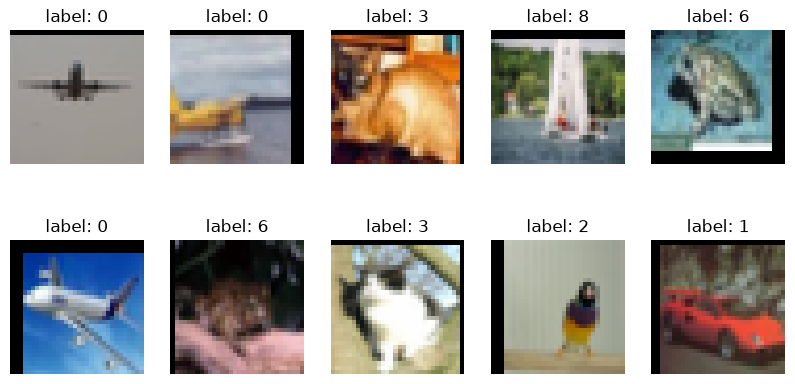

In [ ]:
train_dataset = torchvision.datasets.CIFAR10(root='data', train=True, download=False)
test_dataset = torchvision.datasets.CIFAR10(root='data', train=False, download=False)

print(f"Обучающая выборка: {len(train_dataset)} примеров")
print(f"Тестовая выборка: {len(test_dataset)} примеров")

train_raw = train_dataset.data / 255.0 
train_mean = train_raw.mean(axis=(0, 1, 2))
train_std = train_raw.std(axis=(0, 1, 2))

transform_train = torchvision.transforms.Compose([
    torchvision.transforms.RandomCrop(32, padding=3),
    torchvision.transforms.RandomHorizontalFlip(),
    torchvision.transforms.ToTensor(),
    torchvision.transforms.Normalize(mean=train_mean, std=train_std)
])

transform_test = torchvision.transforms.Compose([
    torchvision.transforms.ToTensor(),
    torchvision.transforms.Normalize(mean=train_mean, std=train_std)
])

train_dataset.transform = transform_train
test_dataset.transform = transform_test

sample_img, sample_label = train_dataset[0]
print(f"Форма изображения после трансформации: {sample_img.shape}")
print(f"Тип метки: {type(sample_label)}, значение: {sample_label}")

fig, axes = plt.subplots(2, 5, figsize=(10, 5))

mean = np.array(train_mean)
std = np.array(train_std)

start_idx = np.random.randint(0, len(train_dataset) - 10);
indices = range(start_idx, start_idx + 10)

for i, ax in zip(indices, axes.flat):
    image, label = train_dataset[i]

    img_plt = image.numpy().transpose((1, 2, 0))
    img_plt = np.clip(std * img_plt + mean, 0, 1)
    
    ax.imshow(img_plt)
    ax.set_title(f'label: {label}')
    ax.axis('off')

plt.show()

In [80]:
class VGG16(torch.nn.Module):
    def __init__(self):
        super(VGG16, self).__init__()
        
        self.relu = torch.nn.ReLU()
        
        self.conv1_1 = torch.nn.Conv2d(in_channels=3, out_channels=64, kernel_size=3, padding=1)
        self.conv1_2 = torch.nn.Conv2d(in_channels=64, out_channels=64, kernel_size=3, padding=1)
        self.pool1 = torch.nn.MaxPool2d(kernel_size=2, stride=2)
        
        self.conv2_1 = torch.nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
        self.conv2_2 = torch.nn.Conv2d(in_channels=128, out_channels=128, kernel_size=3, padding=1)
        self.pool2 = torch.nn.MaxPool2d(kernel_size=2, stride=2)
        
        self.conv3_1 = torch.nn.Conv2d(in_channels=128, out_channels=256, kernel_size=3, padding=1)
        self.conv3_2 = torch.nn.Conv2d(in_channels=256, out_channels=256, kernel_size=3, padding=1)
        self.conv3_3 = torch.nn.Conv2d(in_channels=256, out_channels=256, kernel_size=3, padding=1)
        self.pool3 = torch.nn.MaxPool2d(kernel_size=2, stride=2)
        
        self.conv4_1 = torch.nn.Conv2d(in_channels=256, out_channels=512, kernel_size=3, padding=1)
        self.conv4_2 = torch.nn.Conv2d(in_channels=512, out_channels=512, kernel_size=3, padding=1)
        self.conv4_3 = torch.nn.Conv2d(in_channels=512, out_channels=512, kernel_size=3, padding=1)
        self.pool4 = torch.nn.MaxPool2d(kernel_size=2, stride=2)
        
        self.conv5_1 = torch.nn.Conv2d(in_channels=512, out_channels=512, kernel_size=3, padding=1)
        self.conv5_2 = torch.nn.Conv2d(in_channels=512, out_channels=512, kernel_size=3, padding=1)
        self.conv5_3 = torch.nn.Conv2d(in_channels=512, out_channels=512, kernel_size=3, padding=1)
        self.pool5 = torch.nn.MaxPool2d(kernel_size=2, stride=2)
        
        self.fc1 = torch.nn.Linear(512 * 1 * 1, 512)
        self.fc2 = torch.nn.Linear(512, 512)
        self.fc3 = torch.nn.Linear(512, 10)
        
        self._initialize_weights()


    def forward(self, x):
        out = self.relu(self.conv1_1(x))
        out = self.relu(self.conv1_2(out))
        out = self.pool1(out)

        out = self.relu(self.conv2_1(out))
        out = self.relu(self.conv2_2(out))
        out = self.pool2(out)
    
        out = self.relu(self.conv3_1(out))
        out = self.relu(self.conv3_2(out))
        out = self.relu(self.conv3_3(out))
        out = self.pool3(out)

        out = self.relu(self.conv4_1(out))
        out = self.relu(self.conv4_2(out))
        out = self.relu(self.conv4_3(out))
        out = self.pool4(out)
        
        out = self.relu(self.conv5_1(out))
        out = self.relu(self.conv5_2(out))
        out = self.relu(self.conv5_3(out))
        out = self.pool5(out)
        
        out = torch.flatten(out, 1)
        
        out = self.relu(self.fc1(out))
        out = self.relu(self.fc2(out))
        out = self.fc3(out)
        
        return out


    def _initialize_weights(self):
        for m in self.modules():
            if isinstance(m, torch.nn.Conv2d):
                torch.nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
                if m.bias is not None:
                    torch.nn.init.constant_(m.bias, 0)
            elif isinstance(m, torch.nn.Linear):
                torch.nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
                torch.nn.init.constant_(m.bias, 0)

model = VGG16().to(device)

In [81]:
def evaluate(model, data_loader):
    model.eval()
    tp = 0
    n = 0
    
    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)
            
            outputs = model(images)
            predicted = torch.argmax(outputs, dim=1)
            
            n += labels.size(dim=0)
            tp += (predicted == labels).sum().item()
            
    accuracy = tp / n
    error_rate = 1.0 - accuracy
    return accuracy, error_rate


In [82]:
batch_size = 128
epochs = 20
learning_rate = 0.01

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

loss_function = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

history = {
    'train_err': [],
    'test_err': []
}

for epoch in range(epochs):
    start_time = time.time()
    model.train()
    tp = 0
    n = 0
    
    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        
        outputs = model(images)
        loss = loss_function(outputs, labels)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        predicted = torch.argmax(outputs, dim=1)
        n += labels.size(dim=0)
        tp += (predicted == labels).sum().item()
        
    epoch_time = time.time() - start_time
    
    train_acc = tp / n
    train_err = 1.0 - train_acc
    
    test_acc, test_err = evaluate(model, test_loader)
    
    history['train_err'].append(train_err)
    history['test_err'].append(test_err)
    
    print(f"Эпоха [{epoch + 1}/{epochs}]: "
          f"ошибка на трейне: {train_err * 100:.2f}% | "
          f"точность на трейне: {train_acc * 100:.2f}% | "
          f"время выполнения: {epoch_time:.2f}s")

test_acc, test_err = evaluate(model, test_loader)
print(f"Ошибка на тесте: {test_err * 100:.2f}%")
print(f"Точность на тесте: {test_acc * 100:.2f}%")


Эпоха [1/20]: ошибка на трейне: 70.38% | точность на трейне: 29.62% | время выполнения: 12.92s
Эпоха [2/20]: ошибка на трейне: 59.40% | точность на трейне: 40.60% | время выполнения: 12.61s
Эпоха [3/20]: ошибка на трейне: 53.86% | точность на трейне: 46.14% | время выполнения: 12.74s
Эпоха [4/20]: ошибка на трейне: 48.93% | точность на трейне: 51.07% | время выполнения: 12.71s
Эпоха [5/20]: ошибка на трейне: 45.43% | точность на трейне: 54.57% | время выполнения: 12.75s
Эпоха [6/20]: ошибка на трейне: 42.18% | точность на трейне: 57.82% | время выполнения: 12.65s
Эпоха [7/20]: ошибка на трейне: 39.19% | точность на трейне: 60.81% | время выполнения: 12.38s
Эпоха [8/20]: ошибка на трейне: 36.37% | точность на трейне: 63.63% | время выполнения: 12.41s
Эпоха [9/20]: ошибка на трейне: 34.17% | точность на трейне: 65.83% | время выполнения: 12.48s
Эпоха [10/20]: ошибка на трейне: 31.91% | точность на трейне: 68.09% | время выполнения: 12.62s
Эпоха [11/20]: ошибка на трейне: 30.44% | точност

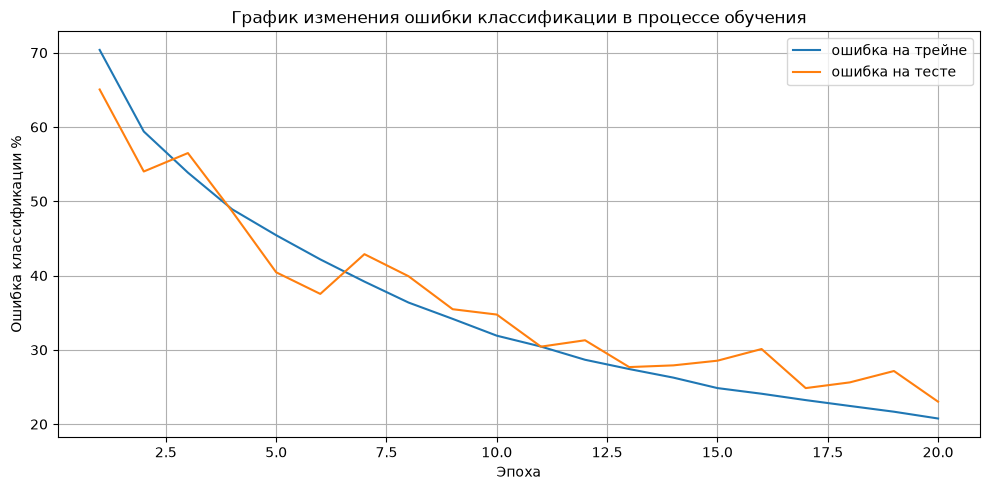

In [83]:
plt.figure(figsize=(10, 5))
plt.plot(range(1, epochs + 1), [e * 100 for e in history['train_err']], label='ошибка на трейне')
plt.plot(range(1, epochs + 1), [e * 100 for e in history['test_err']], label='ошибка на тесте')
plt.title('График изменения ошибки классификации в процессе обучения')
plt.xlabel('Эпоха')
plt.ylabel('Ошибка классификации %')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()
